In [128]:
import numpy as np
from keras import Input
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Dense,Flatten
from tensorflow.keras import  Sequential
from tensorflow.keras.losses import SparseCategoricalCrossentropy
# Load the dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [129]:
x_train.shape

(60000, 28, 28)

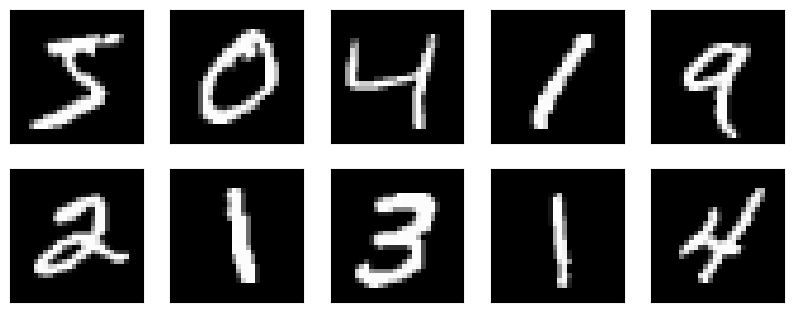

In [130]:
plt.figure(figsize=(10,10))
for i in range(10):
    plt.subplot(5,5,i+1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.xticks([])
    plt.yticks([])
plt.show()

In [131]:
model = Sequential(
    [
        Input(shape=(28, 28)),
        Flatten(),
        Dense(25,activation="relu"),
        Dense(5,activation="relu"),
        Dense(10,activation="softmax")
    ]
)

In [132]:
model.compile(loss=SparseCategoricalCrossentropy, optimizer="adam", metrics=["accuracy"])

In [133]:
X = np.array(x_train)
y = np.array(y_train)
print(x_train.shape)
print(y_train.shape)
print(y_train[0])

(60000, 28, 28)
(60000,)
5


In [134]:
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 25)             │        19,625 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 5)              │           130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 10)             │            60 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,815 (77.40 KB)

 Trainable params: 19,815 (77.40 KB)

 Non-trainable params: 0 (0.00 B)

In [135]:
model.fit(x_train, y_train, epochs=100)

Epoch 1/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 285us/step - accuracy: 0.2175 - loss: 2.2676
Epoch 2/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 279us/step - accuracy: 0.2815 - loss: 1.8444
Epoch 3/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 280us/step - accuracy: 0.3113 - loss: 1.7394
Epoch 4/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 282us/step - accuracy: 0.3920 - loss: 1.4571
Epoch 5/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 279us/step - accuracy: 0.4627 - loss: 1.3037
Epoch 6/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 278us/step - accuracy: 0.5260 - loss: 1.1160
Epoch 7/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 277us/step - accuracy: 0.6863 - loss: 0.7786
Epoch 8/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 274us/step - accuracy: 0.7301 - loss: 0.6510
Epoch 9/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 278us/step - accuracy: 0.7472 - loss: 0.5859
Epoch 10/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 279us/step - accuracy: 0.7495 - loss: 0.5602
Epoch 11/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 279us/step - accuracy: 0.7977 - loss: 0.51

In [136]:
def model_prediction(prediction):
    m = -1
    index = None
    for i in range(10):
        if prediction[0][i]>m:
            m = prediction[0][i]
            index = i
    return index



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


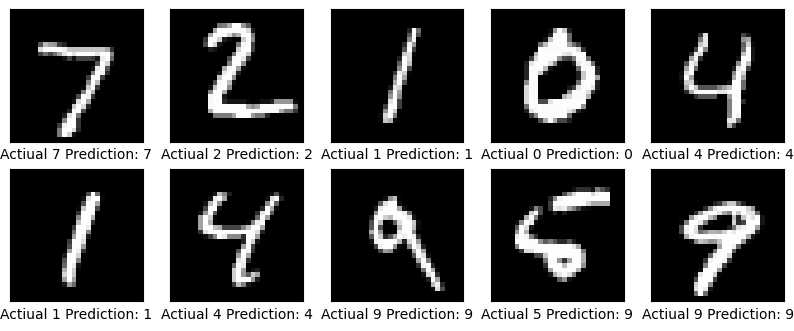

In [137]:
plt.figure(figsize=(10,10))
for i in range(10):
    model_input = x_test[i].reshape(-1,28,28)
    prediction = model_prediction(model.predict(model_input))
    plt.subplot(5,5,i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.xticks([])
    plt.yticks([])
    plt.xlabel(f"Actiual {y_test[i]} Prediction: {prediction}")
plt.show()


In [138]:
test_loss , test_accuracy = model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 252us/step - accuracy: 0.9300 - loss: 0.3780


In [140]:
print(test_loss, test_accuracy)

0.37799620628356934 0.9300000071525574
